## 5: BOUNDARY ANALYSIS


In [1]:
import pandas as pd  
import numpy as np   
import os
import warnings  
warnings.filterwarnings('ignore')

  
import matplotlib.pyplot as plt   
import seaborn as sns   

from sklearn.linear_model import LogisticRegression   
from sklearn.preprocessing import StandardScaler   
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from xgboost import XGBClassifier  
from statsmodels.stats. contingency_tables import mcnemar  

### PATHS & CONFIG

In [2]:
script_dir=os.path.dirname(os.path.abspath('__file__'))
project_dir=os.path.dirname(script_dir)
data_dir=os.path.join(project_dir, 'Data')
output_dir=os.path.join(project_dir, 'Boundary_outputs')
os.makedirs(output_dir, exist_ok=True)

input_path=os.path.join(data_dir, 'crime_features_model.csv')

#Size of test set
N_TEST_MONTHS=8
#top 36 of 359 LSOAs (top 10%)
HOTSPOT_THRESHOLD=36
#Decision threshold from 4_modelling
XGB_THRESHOLD=0.725
RANDOM_STATE=100

# +/- ranks around the threshold to test
ZONE_WIDTHS=[5,10,15,20,25]

sns.set_style('whitegrid')

#Feature columns
FEATURE_COLS = [
    'crime_lag_1', 'crime_lag_2', 'crime_lag_3', 'crime_change', 'crime_rolling_3', 'hotspot_lag_1',
    'spatial_lag_crime', 'spatial_lag_hotspot', 'month_sin', 'month_cos',
    'temp_mean', 'temp_max', 'temp_min', 'rainfall_total', 'rainfall_days',
    'school_holiday_days', 'bank_holiday_days',
    'imd_decile', 'income_decile', 'employment_decile', 'education_decile',
    'health_decile', 'housing_decile', 'living_env_decile',
    'la_Hartlepool', 'la_Middlesbrough', 'la_Redcar and Cleveland', 'la_Stockton-on-Tees'
]

#Deprivation columns
DEP_COLS = ['imd_decile', 'income_decile', 'employment_decile', 'education_decile',
            'health_decile', 'housing_decile', 'living_env_decile']



### LOADING & PREPARING

In [3]:
df=pd.read_csv(input_path)
df=df.sort_values(['LSOA code', 'Month']).reset_index(drop=True)

#Forecasting target: next month's hotspot status
df['hotspot_next']=df.groupby('LSOA code')['hotspot'].shift(-1)

#Next month's crime count for the "are transitions real?" diagnostic
df['crime_next']=df.groupby('LSOA code')['crime_count'].shift(-1)
df=df.dropna(subset=['hotspot_next']).copy()
df['hotspot_next']=df['hotspot_next'].astype(int)

#Filling missing deprivation with median
for col in DEP_COLS:
    if df[col].isna().any():
        df[col]=df[col].fillna(df[col].median())


#Current rank within each month (1=highest crime)
df['rank_now']=df.groupby('Month')['crime_count'].rank(ascending=False, method='first')

months=sorted(df['Month'].unique())

#Defining train/test months and copying data
train=df[df['Month'].isin(months[:-N_TEST_MONTHS])].copy()
test=df[df['Month'].isin(months[-N_TEST_MONTHS:])].copy()

#Defining the train and test set
X_train, y_train=train[FEATURE_COLS], train['hotspot_next']
X_test,y_test=test[FEATURE_COLS], test['hotspot_next']

#Flagging the rows where the area changed status
test['is_transition']=(test['hotspot'] !=test['hotspot_next']).astype(int)

print(f"Train: {months[0]} to {months[-N_TEST_MONTHS-1]} ({len(train):,} rows)")
print(f"Test: {months[-N_TEST_MONTHS]} to {months[-1]} ({len(test):,} rows)")
print(f"Transitions in test set: {test['is_transition'].sum()} "
      f"({test['is_transition'].mean()*100:.1f}%)")



Train: 2023-07 to 2025-06 (8,616 rows)
Test: 2025-07 to 2026-02 (2,872 rows)
Transitions in test set: 152 (5.3%)


### DIAGNOSTIC 1: Are transitions real or threshold artefacts?

Because hotspots are defined by RANK (top 36), an LSOA could flip status without its own crime count meaningfully changing (other areas move around it). If most transitions involve tiny crime changes, they are unpredictable by construction and no feature will capture them

In [4]:
print("DIAGNOSTIC 1: Are transitions real or threshold artefacts?")

#Keepng only the rows where next month's crime count exists
diag=test.dropna(subset=['crime_next']).copy()
#Crime change between this month and next
diag['actual_change']=diag['crime_next']-diag['crime_count']
#Filtering to rows where hotspot status changed
trans=diag[diag['is_transition']==1]
#Absolute size of the swing
abs_change=trans['actual_change'].abs()

print(f"Transitions with next-month data: {len(trans)}")
print(f"Absolute crime change on transition cases:")
for p in [10,25,50,75,90]:
    print(f"{p}th percentile: {np.percentile(abs_change, p):.1f} crimes")
print(f"MEan: {abs_change.mean():.1f} | Median: {abs_change.median():.1f}")

print(f"Proportion of transitions involving only a small change:")

artefact_rows=[]

for t in [1,2,3,5,10]:
    #Counting transitions where the swing was smaller than this threshold
    n=(abs_change <t).sum()
    pct=n/len(trans)*100
    artefact_rows.append({'change_threshold': t, 'n':n, 'pct':pct})
    print(f"Changed by <= {t:2d} crimes: {n:3d}/{len(trans)} = {pct:.1f}%")

#Creating CSV
pd.DataFrame(artefact_rows).to_csv(os.path.join(output_dir,
                                                'diagnostic_transition_magnitude.csv'), index=False)

if (abs_change<=5).mean()>0.3:
    print("--> a large share of transitions are threshold noise.")
else:
    print("--> trnasitions are real, significant changes in crime.")
    


DIAGNOSTIC 1: Are transitions real or threshold artefacts?
Transitions with next-month data: 152
Absolute crime change on transition cases:
10th percentile: 7.0 crimes
25th percentile: 10.0 crimes
50th percentile: 16.0 crimes
75th percentile: 24.0 crimes
90th percentile: 28.9 crimes
MEan: 19.0 | Median: 16.0
Proportion of transitions involving only a small change:
Changed by <=  1 crimes:   0/152 = 0.0%
Changed by <=  2 crimes:   0/152 = 0.0%
Changed by <=  3 crimes:   3/152 = 2.0%
Changed by <=  5 crimes:   7/152 = 4.6%
Changed by <= 10 crimes:  36/152 = 23.7%
--> trnasitions are real, significant changes in crime.


### DIAGNOSTIC 2: Where do transitions occur?

As the transitions are real, we need to see whether they cluster at a specific location in the ranking. If they concentrate near the rank-36 hotspot threshold (the boundary between "hotspot" and "not hotspot"), we can define a narrow zone around that boundary and evaluate the model there.

In [5]:
print("DIAGNOSTIC 2: Where do transitions occur relative to the threshold?")

print(f"(hotspot if rank <= {HOTSPOT_THRESHOLD})")

#Filtering to rows where hotspot status changed
tr=test[test['is_transition']==1]
#Distance of each transitioning LSOAs current rank from the threshold
dist=(tr['rank_now']-HOTSPOT_THRESHOLD).abs()

print(f"\nCurrent rank of transitioning LSOAs: median: {tr['rank_now'].median():.0f} ")
#Checking what proportion of transtions fall within the threshold
for d in[5,10,20,30,50]:
    n=(dist<=d).sum()
    print(f"Within {d:2d} ranks of threshold: {n:3d}/{len(tr)} = {n/len(tr)*100:.1f}%")

DIAGNOSTIC 2: Where do transitions occur relative to the threshold?
(hotspot if rank <= 36)

Current rank of transitioning LSOAs: median: 36 
Within  5 ranks of threshold:  42/152 = 27.6%
Within 10 ranks of threshold:  79/152 = 52.0%
Within 20 ranks of threshold: 124/152 = 81.6%
Within 30 ranks of threshold: 134/152 = 88.2%
Within 50 ranks of threshold: 144/152 = 94.7%


### DIAGNOSTIC 3: Is next-month crime change predictable?

Checking whether the features in the model actually carry signal about what happens next. This is tested by correlating each feature with the actual next-month change in crime. The negatve correlation between month-on-month change and next-month change means: if crime went UP this month, it tends to go DOWN next month --> Mean reversion.

In [6]:
print("DIAGNOSTIC 3: Is next-month crime change predictable?")
corr_rows=[]

#Correlating each feature with the actual next-month crime
for c in ['crime_change', 'crime_rolling_3', 'crime_lag_1', 'spatial_lag_crime', 'crime_count']:
    r=diag[c].corr(diag['actual_change'])
    corr_rows.append({'feature':c, 'corr_with_next_change':r})
    print(f"corr({c:18s}, next-month change) = {r:+.3f}")

#Saving it to CSV
pd.DataFrame(corr_rows).to_csv(os.path.join(output_dir, 'diagnostic_change_correlations.csv'), index=False)

print("\n--> A strong negative value for crime_change indicates MEAN REVERSION")



DIAGNOSTIC 3: Is next-month crime change predictable?
corr(crime_change      , next-month change) = -0.331
corr(crime_rolling_3   , next-month change) = -0.011
corr(crime_lag_1       , next-month change) = -0.034
corr(spatial_lag_crime , next-month change) = -0.019
corr(crime_count       , next-month change) = -0.175

--> A strong negative value for crime_change indicates MEAN REVERSION


### TRAINING MODELS

Persistece baseline, Logistic Regression and XGBoost. ARIMA excluded, as it predicts crime counts for each areas, not hotspot: yes/no.
As the boundary zone is defined by where areas sit in the ranking and ARIMA's prediction are themselves a ranking, comparig would be circular.

In [7]:
spw=(y_train==0).sum()/(y_train==1).sum()

#Standardising features for LR
scaler=StandardScaler()
X_train_s=scaler.fit_transform(X_train)
X_test_s=scaler.transform(X_test)

#Logistic regression with balanced class weights (to handle the 10%)
lr=LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE)
lr.fit(X_train_s, y_train)

#Tuned XGBoost with the configuration from 4_modelling
xgb=XGBClassifier(n_estimators=400, max_depth=4, learning_rate=0.03,
                  subsample=0.8, colsample_bytree=0.8,scale_pos_weight=spw,
                  random_state=RANDOM_STATE, eval_metric='logloss')
xgb.fit(X_train, y_train)

#Predicting
test['pred_baseline']=test['hotspot'].values
test['pred_lr']=lr.predict(X_test_s)
#XGB with the tuned threshold
test['pred_xgb']=(xgb.predict_proba(X_test)[:,1] >= XGB_THRESHOLD).astype(int)

print("Done: persistence baseline, logistic regression, tuned XGBoost")




Done: persistence baseline, logistic regression, tuned XGBoost


### BOUNDARY ZONE SENSITIVITY ANALYSIS

Testing the model's advantage at 5 different widths around the threshold. If the XGBoost advantage over persistence grows as the zone gets tighter (harder cases), it's a valid effect. If it shrinks/disappear --> noise.

In [8]:
print("BOUNDARY ZONE SENSITIVITY:")

print(f"{'Width':>7}{'n':>7}{'Trans%':>8}{'Base%':>7} | {'Persist':>8}{'LogReg':>8}{'XGB':>8} | {'XGB-Persist':>12}")

sens_rows=[]

#Testing at each row width
for width in ZONE_WIDTHS:
    #Defining the zone boundaries around the rank-36 threshold
    lo,hi=HOTSPOT_THRESHOLD - width, HOTSPOT_THRESHOLD + width
    #keeping only test rows whose current rank falls inside this zone
    bz=test[(test['rank_now']>=lo) & (test['rank_now'] <=hi)]
    #skipping if too few rows for accuracy
    if len(bz)<20:
        continue

    #Scoring each model on this row's zone only
    acc_base=accuracy_score(bz['hotspot_next'], bz['pred_baseline'])
    acc_lr=accuracy_score(bz['hotspot_next'], bz['pred_lr'])
    acc_xgb=accuracy_score(bz['hotspot_next'], bz['pred_xgb'])
    #Difference between XGBoost and baseline accuracy
    gap=acc_xgb-acc_base

    sens_rows.append({
        'zone_width': width, 'n':len(bz),
        'transition_rate': bz['is_transition'].mean()*100,
        'base_rate': bz['hotspot_next'].mean()*100,
        'acc_persistence':acc_base, 'acc_logreg':acc_lr, 'acc_xgboost': acc_xgb,
        'xgb_advantage':gap
    })

    print(f"{'+/-' + str(width):>7}{len(bz):>7}{bz['is_transition'].mean()*100:>7.1f}%"
          f"{bz['hotspot_next'].mean()*100:>6.1f}% | {acc_base:>8.3f} {acc_lr:>8.3f}"
          f"{acc_xgb:>8.3f} | {gap:>11.3f}")
    

#Full test set row for contrast
acc_base_all=accuracy_score(y_test, test['pred_baseline'])
acc_lr_all=accuracy_score(y_test, test['pred_lr'])
acc_xgb_all=accuracy_score(y_test, test['pred_xgb'])

print(f"{'ALL':>7}{len(test):>7}{test['is_transition'].mean()*100:>7.1f}%"
      f"{test['hotspot_next'].mean()*100:>6.1f}% | {acc_base_all:>8.3f} {acc_lr_all:>8.3f}"
      f"{acc_xgb_all:>8.3f} | {acc_xgb_all - acc_base_all:>+11.3f}")

#Saving results to CSV
sens_df=pd.DataFrame(sens_rows)
sens_df.to_csv(os.path.join(output_dir, 'boundary_sensitivity.csv'), index=False)

print("\nIf the advantage grows as the zone tightens --> the harder the cases, the more the model contributes.")



BOUNDARY ZONE SENSITIVITY:
  Width      n  Trans%  Base% |  Persist  LogReg     XGB |  XGB-Persist
   +/-5     88   47.7%  43.2% |    0.523    0.500   0.716 |       0.193
  +/-10    168   47.0%  45.8% |    0.530    0.536   0.667 |       0.137
  +/-15    248   43.5%  43.5% |    0.565    0.528   0.653 |       0.089
  +/-20    328   37.8%  44.5% |    0.622    0.567   0.689 |       0.067
  +/-25    408   32.1%  45.8% |    0.679    0.615   0.725 |       0.047
    ALL   2872    5.3%  10.0% |    0.947    0.924   0.952 |      +0.005

If the advantage grows as the zone tightens --> the harder the cases, the more the model contributes.


### FULL METRICS ON THE PRIMARY ZONE (+- 10)

After the proved advantage, committing to one zone (+- 10 ranks around the threshold - ranks 26-46), and reporting full metrics. This is the zone where almost half the rows are transitions and the base rate is near 50% (more balanced than the 90/10 overall balance). A random classifier matched to the zone's base rate is included as a floor. Any model scoring near this has no real discriminative vale.


In [ ]:

#Defining the primary zone 
PRIMARY_WIDTH=10
lo,hi=HOTSPOT_THRESHOLD - PRIMARY_WIDTH, HOTSPOT_THRESHOLD + PRIMARY_WIDTH
#Keepig only the rows where current rank fals within ranks 26-46
bz=test[(test['rank_now']>=lo) & (test['rank_now']<=hi)].copy()

print(f"PRIMARY BOUNDARY ZONE (rank {lo}-{hi}) - full metrics")

print(f"Observations: {len(bz)} ({len(bz)/len(test)*100:.1f}% of test set)")
print(f"Transition rate: {bz['is_transition'].mean()*100:.1f}%")
print(f"Base rate (hotspot next month): {bz['hotspot_next'].mean()*100:.1f}%")

print(f"{'Model':<24}{'Acc':>7}{'Prec':>7}{'Rec':>7}{'F1':>7}")

zone_rows=[]

#Scoring each model on only the boundary-zone rows
for name,col in [('Persistence Baseline', 'pred_baseline'),
                 ('Logistic Regression', 'pred_lr'),
                 ('XGBoost (Tuned)', 'pred_xgb')]:
    a=accuracy_score(bz['hotspot_next'], bz[col])
    p=precision_score(bz['hotspot_next'], bz[col], zero_division=0)
    r=recall_score(bz['hotspot_next'], bz[col], zero_division=0)
    f=f1_score(bz['hotspot_next'], bz[col], zero_division=0)
    zone_rows.append({'model':name, 'accuracy':a, 'precision':p, 'recall':r, 'f1':f})
    print(f"{name:<24}{a:>7.3f}{p:>7.3f}{r:>7.3f}{f:>7.3f}")


# Random classifier, generates predictions matching the zone's base rate 
np.random.seed(1)
random_pred=np.random.binomial(1, bz['hotspot_next'].mean(), len(bz))

#Collecting random pred's results
a=accuracy_score(bz['hotspot_next'], random_pred)
p=precision_score(bz['hotspot_next'], random_pred, zero_division=0)
r=recall_score(bz['hotspot_next'], random_pred, zero_division=0)
f=f1_score(bz['hotspot_next'], random_pred, zero_division=0)

zone_rows.append({'model': 'Random (matched rate)', 'accuracy':a, 'precision':p, 'recall':r, 'f1':f})
print(f"{'Random (matched rate)':<24}{a:>7.3f}{p:>7.3f}{r:>7.3f}{f:>7.3f}")

#Saving results to CSV
pd.DataFrame(zone_rows).to_csv(os.path.join(output_dir, 'boundary_zone_metrics.csv'), index=False)

#scoring the models outside the zone for contrast
out=test[(test['rank_now']<lo) | (test['rank_now']>hi)]
#out = test[(test['rank_now'] < lo) | (test['rank_now'] > hi)]

print(f"\nOUTSIDE the zone (n={len(out)}, transition rate {out['is_transition'].mean()*100:.1f}%):")
print(f"  Persistence Baseline accuracy = {accuracy_score(out['hotspot_next'], out['pred_baseline']):.3f}")
print(f"  XGBoost (tuned)      accuracy = {accuracy_score(out['hotspot_next'], out['pred_xgb']):.3f}")
print("  -> Near-identical.")


PRIMARY BOUNDARY ZONE (rank 26-46) - full metrics
Observations: 168 (5.8% of test set)
Transition rate: 47.0%
Base rate (hotspot next month): 45.8%
Model                       Acc   Prec    Rec     F1
Persistence Baseline      0.530  0.489  0.558  0.521
Logistic Regression       0.536  0.497  0.987  0.661
XGBoost (Tuned)           0.667  0.598  0.831  0.696
Random (matched rate)     0.458  0.410  0.416  0.413

OUTSIDE the zone (n=2704, transition rate 2.7%):
  Persistence Baseline accuracy = 0.973
  XGBoost (tuned)      accuracy = 0.969
  -> Near-identical. This is what inflated the headline results.


### McNemar test: of the cases where the 2 models disagree, does one win more often? 

A higher accuracy could be due to chance with only 168 rows. McNemar test checks this by looking only at the cases where the 2 models disagreed. Then it counts how many of those disagreements each model won and calcuates whether the split is too one-sided to be caused by chance. The test is repeated at 3 zone widths to confirm the result is not specific to one zone definition.

In [10]:
print("McNEMAR TEST: is XGBoost significantly better than persistence?")

mcnemar_rows=[]

#Runing the test at 3 zone widths
for width in [10,15,20]:
    #Defining the zone for this width
    lo_w, hi_w=HOTSPOT_THRESHOLD - width, HOTSPOT_THRESHOLD + width
    z=test[(test['rank_now'] >=lo_w) & (test['rank_now'] <=hi_w)]
    #selecting which rows each model got rigth
    base_ok=(z['pred_baseline'] == z['hotspot_next'])
    xgb_ok=(z['pred_xgb'] == z['hotspot_next'])

    #Both right
    n11=(base_ok & xgb_ok).sum()
    #Baseline right, XGB wrong
    n10=(base_ok & ~xgb_ok).sum()
    #XGB right, baseline wrong
    n01=(~base_ok & xgb_ok).sum()
    #Both wrong
    n00=(~base_ok & ~xgb_ok).sum()

    #Assigning results, exact=True -> when disagreement counts are small
    result=mcnemar([[n11, n10], [n01, n00]], exact=True)
    sig="SIGNIFICANT" if result.pvalue<0.05 else "not significant"

    mcnemar_rows.append({
        'zone_width': width, 'n':len(z),
        'xgb_right_base_wrong': n01, 'base_right_xgb_wrong': n10,
        'p_value': result.pvalue, 'significant':result.pvalue<0.05
    })

    print(f"Zone +/-{width:2d} (n={len(z):3d}): XGB right & base wrong={n01:3d} | "
          f"base right & XGB wrong = {n10:3d} | p={result.pvalue:.4f} --> {sig}")
    
#Saving results to CSV
pd.DataFrame(mcnemar_rows).to_csv(os.path.join(output_dir, 'mcnemar_tests.csv'), index=False)



McNEMAR TEST: is XGBoost significantly better than persistence?
Zone +/-10 (n=168): XGB right & base wrong= 45 | base right & XGB wrong =  22 | p=0.0067 --> SIGNIFICANT
Zone +/-15 (n=248): XGB right & base wrong= 54 | base right & XGB wrong =  32 | p=0.0230 --> SIGNIFICANT
Zone +/-20 (n=328): XGB right & base wrong= 57 | base right & XGB wrong =  35 | p=0.0280 --> SIGNIFICANT


### Plot 1: Transition rate by rank band

Plot 1: Transition rate by rank band


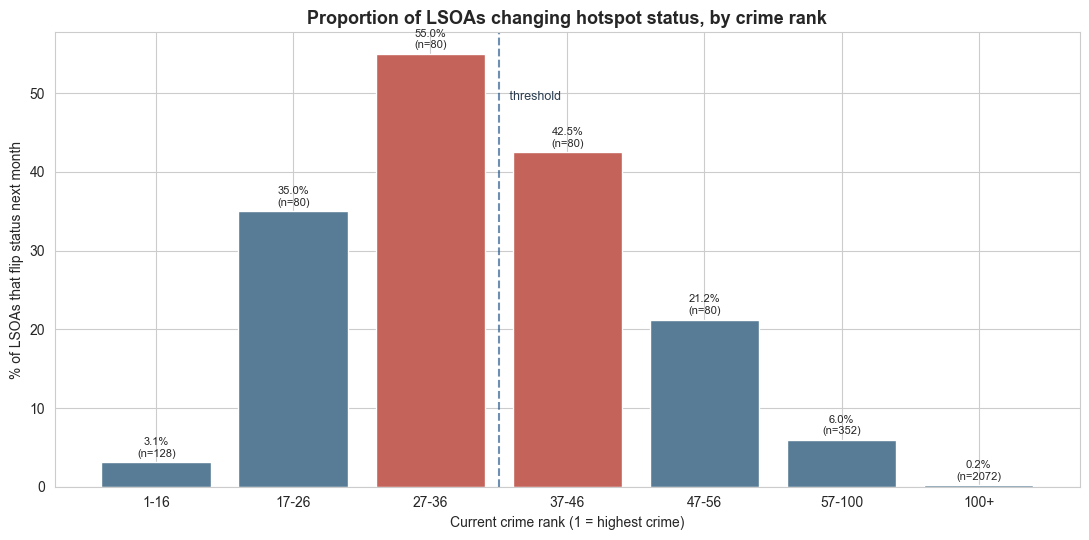

Saved Plot_1_transition_by_rank.png


In [11]:

print("Plot 1: Transition rate by rank band")

test['rank_band'] = pd.cut(test['rank_now'],
                           bins=[0, 16, 26, 36, 46, 56, 100, 400],
                           labels=['1-16', '17-26', '27-36', '37-46', '47-56', '57-100', '100+'])

band_rates = test.groupby('rank_band')['is_transition'].agg(['mean', 'count'])

band_rates['mean'] *= 100

fig, ax = plt.subplots(figsize=(11, 5.5))
colors = ["#587c95" if not ('27-36' in str(b) or '37-46' in str(b)) else "#c46359"
          for b in band_rates.index]
ax.bar(range(len(band_rates)), band_rates['mean'], color=colors, edgecolor='white')
ax.set_xticks(range(len(band_rates)))
ax.set_xticklabels(band_rates.index)
ax.set_xlabel('Current crime rank (1 = highest crime)')
ax.set_ylabel('% of LSOAs that flip status next month')
ax.set_title(f'Proportion of LSOAs changing hotspot status, by crime rank',
             fontsize=13, fontweight='bold')
for i, (v, n) in enumerate(zip(band_rates['mean'], band_rates['count'])):
    ax.text(i, v + 0.7, f'{v:.1f}%\n(n={n})', ha='center', fontsize=8)
ax.axvline(2.5, color="#0d457e", linestyle='--', alpha=0.6)
ax.text(2.55, ax.get_ylim()[1] * 0.85, ' threshold', fontsize=9, color='#2c3e50')
plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'Plot_1_transition_by_rank.png'), dpi=150)
plt.show()

print("Saved Plot_1_transition_by_rank.png")

Plot 2: Zone sensitivity

Plot 2: Zone sensitivity


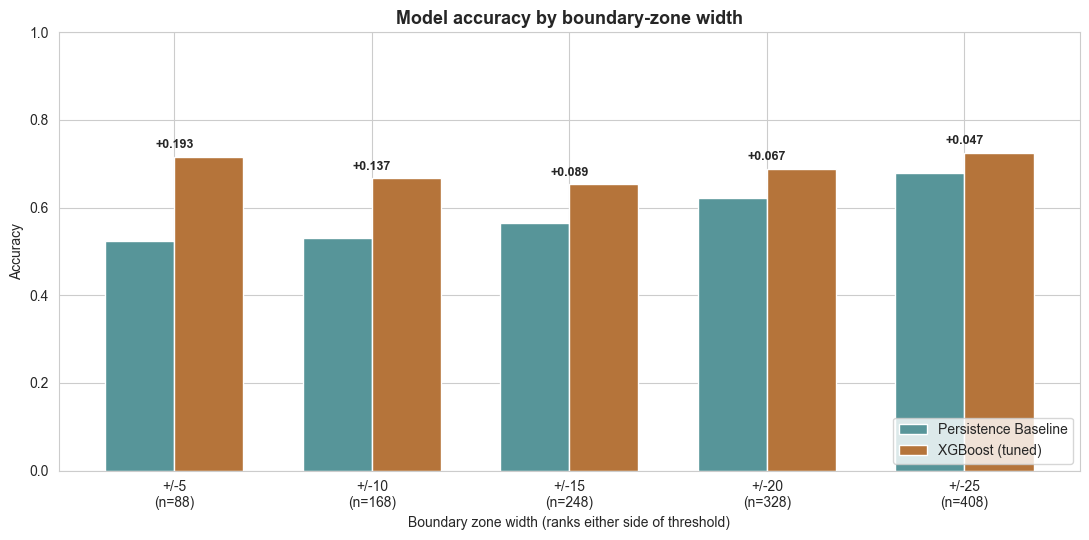

Saved Plot_2_zone_sensitivity.png


In [12]:
print("Plot 2: Zone sensitivity")

fig, ax = plt.subplots(figsize=(11, 5.5))
x = np.arange(len(sens_df))
width_bar = 0.35
ax.bar(x - width_bar/2, sens_df['acc_persistence'], width_bar,
       label='Persistence Baseline', color="#579599", edgecolor='white')
ax.bar(x + width_bar/2, sens_df['acc_xgboost'], width_bar,
       label='XGBoost (tuned)', color="#b5743a", edgecolor='white')
for i, row in sens_df.iterrows():
    ax.text(i, max(row['acc_persistence'], row['acc_xgboost']) + 0.02,
            f"+{row['xgb_advantage']:.3f}", ha='center', fontsize=9, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels([f"+/-{int(w)}\n(n={int(n)})" for w, n in zip(sens_df['zone_width'], sens_df['n'])])
ax.set_xlabel('Boundary zone width (ranks either side of threshold)')
ax.set_ylabel('Accuracy')
ax.set_title('Model accuracy by boundary-zone width',
             fontsize=13, fontweight='bold')
ax.legend(loc='lower right')
ax.set_ylim(0, 1.0)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'Plot_2_zone_sensitivity.png'), dpi=150)
plt.show()

print("Saved Plot_2_zone_sensitivity.png")

### Plot 3: Headline vs reality

Plot 3: Headline vs reality


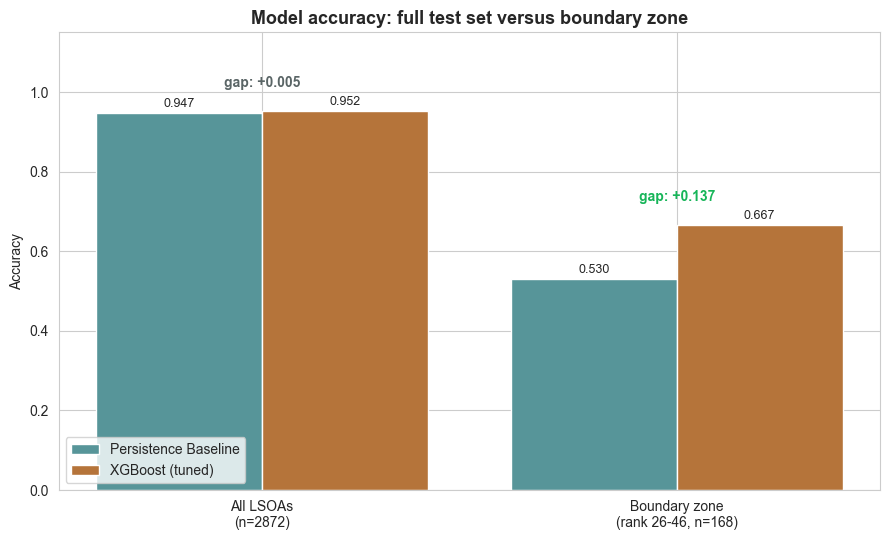

Saved Plot_3_headline_vs_reality.png


In [13]:
print("Plot 3: Headline vs reality")

fig, ax = plt.subplots(figsize=(9, 5.5))
groups = ['All LSOAs\n(n=%d)' % len(test), f'Boundary zone\n(rank {lo}-{hi}, n={len(bz)})']
persist_vals = [acc_base_all, accuracy_score(bz['hotspot_next'], bz['pred_baseline'])]
xgb_vals = [acc_xgb_all, accuracy_score(bz['hotspot_next'], bz['pred_xgb'])]

x = np.arange(2)
ax.bar(x - 0.2, persist_vals, 0.4, label='Persistence Baseline', color='#579599', edgecolor='white')
ax.bar(x + 0.2, xgb_vals, 0.4, label='XGBoost (tuned)', color='#b5743a', edgecolor='white')
for i in range(2):
    ax.text(x[i] - 0.2, persist_vals[i] + 0.015, f'{persist_vals[i]:.3f}', ha='center', fontsize=9)
    ax.text(x[i] + 0.2, xgb_vals[i] + 0.015, f'{xgb_vals[i]:.3f}', ha='center', fontsize=9)
    gap = xgb_vals[i] - persist_vals[i]
    ax.text(x[i], max(persist_vals[i], xgb_vals[i]) + 0.06,
            f'gap: {gap:+.3f}', ha='center', fontsize=10, fontweight='bold',
            color="#17b559" if gap > 0.05 else "#5a6566")
ax.set_xticks(x)
ax.set_xticklabels(groups)
ax.set_ylabel('Accuracy')
ax.set_title('Model accuracy: full test set versus boundary zone',
             fontsize=13, fontweight='bold')
ax.legend(loc='lower left')
ax.set_ylim(0, 1.15)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'Plot_3_headline_vs_reality.png'), dpi=150)
plt.show()

print("Saved Plot_3_headline_vs_reality.png")

